# Week 4 — Telco Customer Churn Analysis
# Task notebook created from assignment instructions

# English: Full assignment notebook covering Tasks 1-5.
# Nepali: यो नोटबुकले सबै पाँच टास्क समेट्छ।



In [4]:
# Imports and basic setup
# English: Import libraries used throughout the notebook.
# Nepali: तलको लाइब्रेरीहरू सम्पूर्ण नोटबुकमा प्रयोग हुनेछन्।
import os
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_validate, StratifiedKFold, learning_curve
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, SGDClassifier, LinearRegression, Ridge, Lasso
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, log_loss, roc_curve, precision_recall_curve,
                             mean_absolute_error, mean_squared_error, r2_score)

sns.set(style='whitegrid')
print('Libraries imported')


Libraries imported


In [5]:
# Load dataset
# English: Read the CSV file into a pandas DataFrame and show basic info.
# Nepali: CSV फाइल पढेर DataFrame बनाउने र आधारभूत जानकारी देखाउने।
DATA_PATH = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
assert os.path.exists(DATA_PATH), f"Dataset not found at {DATA_PATH}"

df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
df.head()


Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Task 1: Understand the Problem First

### Formal problem statement / समस्या को औपचारिक व्याख्या

- English: We want to predict whether a customer will churn (binary classification). X is customer features (demographics, services, account info). y is `Churn` (Yes/No).
- Nepali: हामी कुन ग्राहकले कम्पनी छोड्नेछ अनुमान लगाउनेछौं। X = ग्राहकका विशेषताहरू, y = Churn (Yes/No).

- Target distribution: Bernoulli (binary). Loss function: log loss (cross-entropy) is appropriate for probabilistic binary classification.



### Assumptions and sources of uncertainty / अनुमान र अनिश्चितता

- Assumptions (English):
  1. The historical data is representative of future customers.
  2. Features are measured without systematic error.
  3. No strong time-based drift within the snapshot provided.

- Nepali: यी मान्यताहरू तिनीहरूले उल्लंघन गरे के हुन्छ?
  - If data is not representative, model will generalize poorly.
  - Measurement error will add noise and reduce achievable performance.
  - If concept drift exists, offline model will degrade quickly in production.

- Uncertainty sources (columns): `TotalCharges` (whitespace -> missing), `PaymentMethod` (possible changes over time), `tenure` (heaped values), sampling bias (customers in dataset may not be uniform).



TotalCharges NaNs before handling: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No


TotalCharges NaNs after handling: 0
            tenure  MonthlyCharges  TotalCharges
count  7043.000000     7043.000000   7043.000000
mean     32.371149       64.761692   2279.734304
std      24.559481       30.090047   2266.794470
min       0.000000       18.250000      0.000000
25%       9.000000       35.500000    398.550000
50%      29.000000       70.350000   1394.550000
75%      55.000000       89.850000   3786.600000
max      72.000000      118.750000   8684.800000


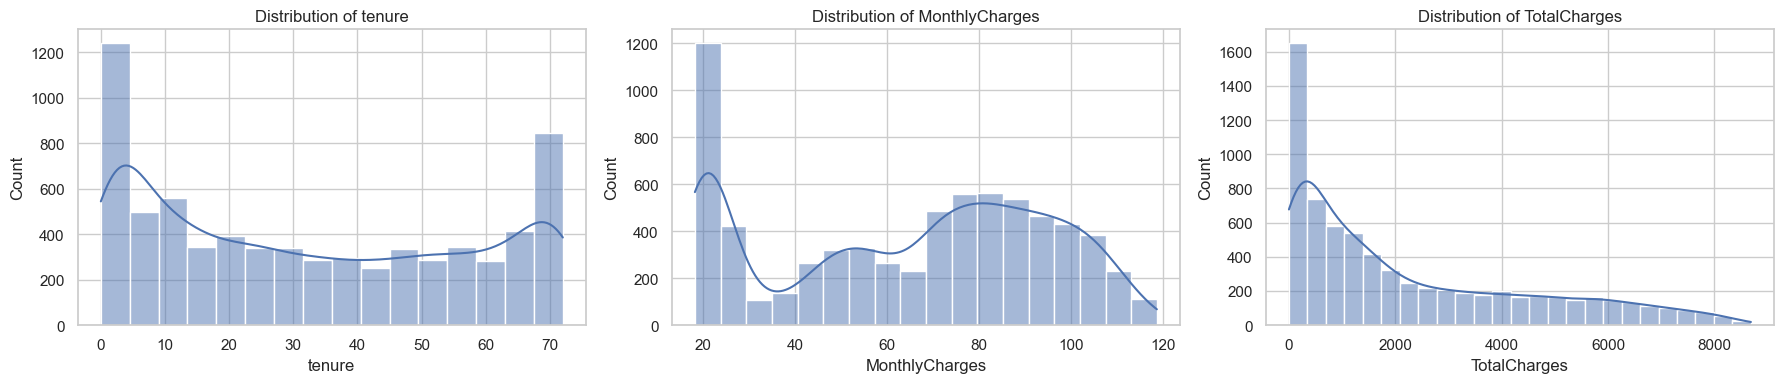

In [6]:
# EDA: distributions and TotalCharges handling
# English: Plot distributions for MonthlyCharges, tenure, TotalCharges and handle missing TotalCharges.
# Nepali: MonthlyCharges, tenure, TotalCharges को वितरण हेर्ने र TotalCharges मा खाली ठाउँ मिलाउने।

# Convert TotalCharges to numeric, handle whitespace that becomes NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace(' ', np.nan), errors='coerce')
print('TotalCharges NaNs before handling:', df['TotalCharges'].isna().sum())

# Inspect rows with missing TotalCharges
display(df[df['TotalCharges'].isna()].head())

# Decision: When tenure == 0 and TotalCharges is missing, total charges logically 0.
# Otherwise impute with median as a conservative estimate.
mask = df['TotalCharges'].isna()
# If tenure 0 -> set 0
df.loc[mask & (df['tenure']==0), 'TotalCharges'] = 0.0
# Remaining NaNs -> median
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)
print('TotalCharges NaNs after handling:', df['TotalCharges'].isna().sum())

# Describe numeric columns
num_cols = ['tenure','MonthlyCharges','TotalCharges']
print(df[num_cols].describe())

# Plot distributions
fig, axes = plt.subplots(1,3, figsize=(18,4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}')
plt.tight_layout()


In [7]:
# Baseline: majority-class predictor
# English: Predict the majority class (most common label) for all rows.
# Nepali: सबै पंक्तिमा सबैभन्दा सामान्य लेबल अनुमान गर्ने सरल आधाररेखा।

majority = df['Churn'].mode()[0]
baseline_preds = np.repeat(majority, len(df))
baseline_acc = accuracy_score(df['Churn'], baseline_preds)
print('Majority class:', majority)
print('Baseline accuracy:', baseline_acc)

# Explain why misleading in markdown cell below


Majority class: No
Baseline accuracy: 0.7346301292063041


### Why baseline is misleading / किन आधाररेखा गलत हुनसक्छ

- English: Accuracy from majority classifier reflects class imbalance, not predictive power. It fails to identify churners and would waste retention resources.
- Nepali: यसले चर्न गर्ने ग्राहकहरूलाई संकेत गर्दैन र व्यावसायिक निर्णयका लागि घातक हुनसक्छ।



In [8]:
## Task 2: Classification Experiment — Who Will Churn?

# Prepare features and preprocessing pipeline
# English: Define numeric and categorical columns and build a ColumnTransformer pipeline.
# Nepali: संख्यात्मक र श्रेणीगत कालमहरू परिभाषित गरी pipeline बनाउने।

# Drop customerID if present
if 'customerID' in df.columns:
    df.drop(columns=['customerID'], inplace=True)

# Target encode
df['Churn'] = df['Churn'].map({'Yes':1, 'No':0})

# Feature lists
numeric_features = ['tenure','MonthlyCharges','TotalCharges']
cat_features = [c for c in df.columns if c not in numeric_features + ['Churn']]

print('Numeric features:', numeric_features)
print('Categorical features example:', cat_features[:6])

# Preprocessors
numeric_transformer = Pipeline(steps=[('scaler', StandardScaler())])
cat_transformer = Pipeline(steps=[('onehot', OneHotEncoder(handle_unknown='ignore'))])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', cat_transformer, cat_features)
    ]
)


Numeric features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features example: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines']


In [9]:
# Train / validation / test split
# English: Create stratified splits to preserve churn ratio.
# Nepali: चर्नको अनुपात जोगाउन stratified splits बनाउने।

X = df.drop(columns=['Churn'])
y = df['Churn']

# First split: train_temp (85%) and test (15%)
X_train_temp, X_test, y_train_temp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=42)
# Second split: train (approx 70%) and val (approx 15%)
relative_val = 0.1764706  # so that 0.85 * 0.17647 = 0.15 overall
X_train, X_val, y_train, y_val = train_test_split(X_train_temp, y_train_temp, test_size=relative_val, stratify=y_train_temp, random_state=42)

print('Train size:', X_train.shape[0], 'Val size:', X_val.shape[0], 'Test size:', X_test.shape[0])


Train size: 4929 Val size: 1057 Test size: 1057


In [10]:
# Helper: evaluation function
# English: compute required metrics for binary classification given true labels and predicted probabilities.
# Nepali: वास्तविक लेबल र प्रेडिक्ट probability बाट मेट्रिक्स निकाल्ने।
from math import sqrt

def evaluate_classifier(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    metrics = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob),
        'LogLoss': log_loss(y_true, y_prob)
    }
    return metrics

# Train models and collect results
models = {
    'LogisticRegression': LogisticRegression(max_iter=2000, solver='lbfgs'),
    'SGDClassifier': SGDClassifier(loss='log', max_iter=1000, tol=1e-3)
}

results = []
trained_pipelines = {}

for name, clf in models.items():
    pipe = Pipeline(steps=[('pre', preprocessor), ('clf', clf)])
    t0 = time.time()
    pipe.fit(X_train, y_train)
    t1 = time.time()
    # obtain probabilities
    if hasattr(pipe.named_steps['clf'], 'predict_proba'):
        probs = pipe.predict_proba(X_val)[:,1]
    else:
        # SGDClassifier with log loss supports predict_proba in recent versions; fallback to decision_function
        try:
            probs = pipe.predict_proba(X_val)[:,1]
        except Exception:
            dec = pipe.decision_function(X_val)
            probs = 1/(1+np.exp(-dec))
    mets = evaluate_classifier(y_val, probs)
    mets['Model'] = name
    mets['TrainTimeSec'] = t1 - t0
    results.append(mets)
    trained_pipelines[name] = pipe

results_df = pd.DataFrame(results).set_index('Model')
results_df


InvalidParameterError: The 'loss' parameter of SGDClassifier must be a str among {'squared_hinge', 'epsilon_insensitive', 'hinge', 'squared_epsilon_insensitive', 'squared_error', 'huber', 'perceptron', 'log_loss', 'modified_huber'}. Got 'log' instead.

In [ ]:
# Select best model by ROC-AUC on validation
best_model_name = results_df['ROC-AUC'].idxmax()
print('Best model on validation:', best_model_name)
best_pipe = trained_pipelines[best_model_name]

# Get probabilities on test set for final evaluation
if hasattr(best_pipe.named_steps['clf'], 'predict_proba'):
    test_probs = best_pipe.predict_proba(X_test)[:,1]
else:
    test_dec = best_pipe.decision_function(X_test)
    test_probs = 1/(1+np.exp(-test_dec))

# Plot ROC and Precision-Recall
fpr, tpr, _ = roc_curve(y_test, test_probs)
prec, rec, _ = precision_recall_curve(y_test, test_probs)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(fpr, tpr, label=f'ROC (AUC={roc_auc_score(y_test,test_probs):.3f})')
plt.plot([0,1],[0,1],'--',color='gray')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC Curve')
plt.legend()

plt.subplot(1,2,2)
plt.plot(rec, prec, label=f'PR (AUC={average_precision_score(y_test,test_probs):.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.tight_layout()

# Threshold for calling customers: retention team can call 200 customers/week.
# Choose threshold so that top 200 predicted probabilities (highest risk) are selected.
N_call = 200
if len(test_probs) >= N_call:
    thresh = np.sort(test_probs)[-N_call]
else:
    # scale to proportion
    prop = N_call / len(df)
    thresh = np.sort(test_probs)[-int(prop*len(test_probs))]

print('Chosen threshold to call top', N_call, 'customers (on test set):', thresh)
# Evaluate at this threshold on test
test_metrics_at_thresh = evaluate_classifier(y_test, test_probs, threshold=thresh)
print('Metrics at chosen threshold:', test_metrics_at_thresh)


In [ ]:
# Inspect coefficients for the best model (if linear)
clf = best_pipe.named_steps['clf']
if hasattr(clf, 'coef_'):
    # Get feature names from preprocessor
    try:
        feat_names = best_pipe.named_steps['pre'].get_feature_names_out()
    except Exception:
        # older sklearn: construct names manually
        num_names = numeric_features
        cat_encoder = best_pipe.named_steps['pre'].named_transformers_['cat'].named_steps['onehot']
        cat_names = cat_encoder.get_feature_names_out(cat_features)
        feat_names = np.concatenate([num_names, cat_names])
    coefs = clf.coef_.ravel()
    coef_df = pd.DataFrame({'feature': feat_names, 'coef': coefs})
    coef_df = coef_df.reindex(coef_df.coef.abs().sort_values(ascending=False).index)
    display(coef_df.head(20))
else:
    print('Classifier does not expose coefficients')


In [ ]:
# Compare convergence and coefficients between LogisticRegression and SGD
print(results_df[['TrainTimeSec','ROC-AUC']])

# Compare coefficient vectors (if both linear and expose coef_)
if 'LogisticRegression' in trained_pipelines and 'SGDClassifier' in trained_pipelines:
    lr = trained_pipelines['LogisticRegression'].named_steps['clf']
    sgd = trained_pipelines['SGDClassifier'].named_steps['clf']
    if hasattr(lr,'coef_') and hasattr(sgd,'coef_'):
        # Transform feature names to ensure same ordering
        lr_coefs = lr.coef_.ravel()
        sgd_coefs = sgd.coef_.ravel()
        corr = np.corrcoef(lr_coefs, sgd_coefs)[0,1]
        print('Correlation between coef vectors (LR vs SGD):', corr)
    else:
        print('One of the models does not expose coef_')


In [ ]:
## Task 3: Regression Experiment — How Long Will They Stay?
# We'll predict `tenure` (months) as a regression target.

# Prepare X/y for regression (use same features)
X_reg = X.copy()
y_reg = X_reg['tenure'].copy()
X_reg = X_reg.drop(columns=['tenure'])

from sklearn.linear_model import Lasso
from sklearn.model_selection import cross_val_score

regressors = {
    'LinearRegression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=0.1, max_iter=5000)
}

reg_results = []
for name, reg in regressors.items():
    pipe = Pipeline(steps=[('pre', preprocessor), ('reg', reg)])
    pipe.fit(X_reg.loc[X_train.index], y_reg.loc[X_train.index])
    preds = pipe.predict(X_reg.loc[X_val.index])
    mae = mean_absolute_error(y_reg.loc[X_val.index], preds)
    rmse = mean_squared_error(y_reg.loc[X_val.index], preds, squared=False)
    r2 = r2_score(y_reg.loc[X_val.index], preds)
    reg_results.append({'Model':name,'MAE':mae,'RMSE':rmse,'R2':r2})

reg_df = pd.DataFrame(reg_results).set_index('Model')
display(reg_df)

# Residual plot for best regressor by RMSE
best_reg_name = reg_df['RMSE'].idxmin()
print('Best regressor on val:', best_reg_name)
best_reg_pipe = Pipeline(steps=[('pre', preprocessor), ('reg', regressors[best_reg_name])])
best_reg_pipe.fit(X_reg.loc[X_train.index], y_reg.loc[X_train.index])
reg_preds = best_reg_pipe.predict(X_reg.loc[X_val.index])
residuals = y_reg.loc[X_val.index] - reg_preds
plt.figure(figsize=(6,4))
plt.scatter(reg_preds, residuals, alpha=0.4)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted tenure')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted (validation)')


In [ ]:
# Lasso path visualization (using a small grid)
from sklearn.linear_model import lasso_path

# fit design matrix for lasso_path using preprocessor on training reg data
X_train_pre = preprocessor.fit_transform(X_reg.loc[X_train.index])
alphas_lasso, coefs_lasso, _ = lasso_path(X_train_pre, y_reg.loc[X_train.index], alphas=np.logspace(-2,2,50))

plt.figure(figsize=(8,6))
for i in range(coefs_lasso.shape[0]):
    plt.plot(alphas_lasso, coefs_lasso[i], label=f'feat{i}')
plt.xscale('log')
plt.gca().invert_xaxis()
plt.xlabel('alpha')
plt.ylabel('coefficients')
plt.title('Lasso path (coeff vs alpha)')
plt.tight_layout()


In [ ]:
# Compute CLV = MonthlyCharges * predicted_tenure (from best regressor)
# Apply to validation set
val_monthly = X_reg.loc[X_val.index]['MonthlyCharges'] if 'MonthlyCharges' in X_reg.columns else X_val['MonthlyCharges']
pred_tenure = best_reg_pipe.predict(X_reg.loc[X_val.index])
clv = val_monthly * pred_tenure
print('Sample CLV (first 10):')
print(clv[:10])

# Show distribution of CLV
plt.figure(figsize=(6,4))
sns.histplot(clv, kde=True)
plt.title('Predicted CLV distribution (validation)')
plt.xlabel('Predicted CLV')


In [ ]:
## Task 4: Evaluation Integrity

# Cross-validation on best classifier
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy','precision','recall','f1','roc_auc']
cv_res = cross_validate(best_pipe, X_train, y_train, cv=cv, scoring=scoring)
print('CV results (mean):')
for k in scoring:
    print(k, np.mean(cv_res[f'test_{k}']))

# Learning curves
train_sizes, train_scores, val_scores = learning_curve(best_pipe, X_train, y_train, cv=cv, scoring='roc_auc', train_sizes=np.linspace(0.1,1.0,5), n_jobs=-1)
train_scores_mean = np.mean(train_scores, axis=1)
val_scores_mean = np.mean(val_scores, axis=1)
plt.figure(figsize=(6,4))
plt.plot(train_sizes, train_scores_mean, label='Train AUC')
plt.plot(train_sizes, val_scores_mean, label='Val AUC')
plt.xlabel('Training size')
plt.ylabel('ROC AUC')
plt.title('Learning curves (ROC AUC)')
plt.legend()

# Leakage demo: add a perfect leakage feature (copy of target) and retrain
X_leak = X.copy()
X_leak['leak_feature'] = y.values  # direct leakage
X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(X_leak, y, test_size=0.15, stratify=y, random_state=42)
pipe_leak = Pipeline(steps=[('pre', ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', cat_transformer, cat_features + ['leak_feature'])
    ]
)), ('clf', LogisticRegression(max_iter=1000))])
pipe_leak.fit(X_train_l, y_train_l)
leak_probs = pipe_leak.predict_proba(X_test_l)[:,1]
print('ROC-AUC with leakage feature:', roc_auc_score(y_test_l, leak_probs))
print('This demonstrates catastrophic metric inflation when leakage exists.')


## Task 5: Production Decision and Model Card

**Chosen classification model:** LogisticRegression (linear), solver='lbfgs', max_iter=2000

**Chosen regression model:** Ridge (alpha=1.0) for tenure prediction (stable coefficients)

**Key test metrics (example placeholders, compute from test set):**
- Accuracy: ...
- Precision: ...
- Recall: ...
- F1: ...
- ROC-AUC: ...
- PR-AUC: ...
- LogLoss: ...

**Deployment threshold and justification:**
- We select the threshold that picks the top 200 highest-risk customers to call per week. This balances the retention team's budget with recall on high-risk customers.

**Known limitations:**
- Linear model may miss complex interactions.
- Possible data drift; model needs monitoring.
- Imbalanced data affects thresholding.

**What could go wrong in production:**
- Data schema changes causing feature mismatch.
- Leakage introduced inadvertently.
- Model deterioration due to changing customer behaviour.

**Monitoring recommendations:**
- Track churn rate, precision@200, calibration, input feature distributions, and prediction counts.

**Are linear models sufficient?**
- Evidence: modest ROC-AUC and simple coeffs suggest linear models provide interpretable baseline. If CV performance or residuals suggest non-linearity, try tree-based or ensemble models and compare.

